# Multimodal — Gambar + Tabel (embedding gambar digabung kolom tabel)
**Kapan dipakai:** tiap baris punya foto DAN kolom tabel: foto produk + harga/berat, foto
rumah + luas/lokasi, rontgen + data pasien.

**Idenya:** gambar diubah jadi embedding (deretan angka) oleh model pretrained yang tidak
dilatih ulang. Kolom tabel di-log, disamakan skalanya, kategori di-one-hot. Keduanya
**digabung jadi satu tabel** lalu dilatih satu model ("early fusion").

**Langkah:**
1. Embedding gambar train dan test.
2. Olah kolom tabel, gabungkan dengan embedding.
3. Latih model, evaluasi F1, buat submission.

**Data demo:** CIFAR-10 kecil + kolom acak `berat_kg`, `panjang_m`, `kecepatan_kmj`,
`warna_dominan` (sengaja tidak berguna, jadi "tabel saja" seharusnya lemah).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from lightgbm import LGBMClassifier
from PIL import Image
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from torch import nn
from torch.nn import functional
from torchvision import models

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/multimodal"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/gambar_tabular/train.csv"
TEST_CSV = f"{DATA_FOLDER}/gambar_tabular/test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/gambar_tabular/test_labels.csv"   # hanya ada di data latihan
PRETRAINED = "Z:/GEMASTIK-DATABASE/pretrained"

ID_COL = "id"
PATH_COL = "path"       # path gambar, relatif terhadap DATA_FOLDER
TARGET = "label"
NUMBER_COLS = ["berat_kg", "panjang_m", "kecepatan_kmj"]
CATEGORY_COLS = ["warna_dominan"]
IMAGE_SIZE = 224
BATCH_SIZE = 128
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406])
MEAN = MEAN.view(1, 3, 1, 1).to(DEVICE)    # normalisasi warna ImageNet
STD = torch.tensor([0.229, 0.224, 0.225])
STD = STD.view(1, 3, 1, 1).to(DEVICE)

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train[TARGET].value_counts())
train.head()

train: (4000, 7) | test: (1000, 6)
label
airplane      400
automobile    400
bird          400
cat           400
deer          400
dog           400
frog          400
horse         400
ship          400
truck         400
Name: count, dtype: int64


,id,path,berat_kg,panjang_m,kecepatan_kmj,warna_dominan,label
0,0,../vision/classification/cifar10_small/train/a...,12965.32,52.04,581.41,biru,airplane
1,1,../vision/classification/cifar10_small/train/a...,11437.42,48.92,1605.44,hijau,airplane
2,2,../vision/classification/cifar10_small/train/a...,10989.96,36.82,1644.36,hijau,airplane
3,3,../vision/classification/cifar10_small/train/a...,34861.42,15.43,403.93,abu,airplane
4,4,../vision/classification/cifar10_small/train/a...,23998.52,10.65,802.95,merah,airplane


## Langkah 1a — backbone pretrained beku
Lapisan klasifikasi terakhir diganti `nn.Identity()` supaya keluarannya embedding.
Pilih SATU blok: hapus `#` di blok yang ingin dipakai, beri `#` pada blok resnet50.

In [4]:
backbone = models.resnet50(weights=None)
backbone.load_state_dict(torch.load(f"{PRETRAINED}/resnet50/model.pth", map_location="cpu"))
backbone.fc = nn.Identity()

# backbone = models.convnext_tiny(weights=None)
# backbone.load_state_dict(torch.load(f"{PRETRAINED}/convnext_tiny/model.pth",
#                                     map_location="cpu"))
# backbone.classifier[2] = nn.Identity()

# backbone = models.resnet18(weights=None)     # paling cepat
# backbone.load_state_dict(torch.load(f"{PRETRAINED}/resnet18/model.pth", map_location="cpu"))
# backbone.fc = nn.Identity()

backbone = backbone.to(DEVICE)
backbone.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

## Langkah 1b — embedding semua gambar
Gambar → tensor 0–1 → diperbesar ke `IMAGE_SIZE` → dinormalisasi → backbone.

In [5]:
def embed_images(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        arrays = []
        for path in paths[start:start + BATCH_SIZE]:
            arrays.append(np.asarray(Image.open(f"{DATA_FOLDER}/{path}").convert("RGB")))
        batch = torch.tensor(np.stack(arrays)).permute(0, 3, 1, 2)
        batch = batch.float().to(DEVICE) / 255
        batch = functional.interpolate(batch, size=IMAGE_SIZE, mode="bilinear")
        with torch.no_grad():
            batches.append(backbone((batch - MEAN) / STD).cpu())
    return torch.cat(batches).numpy()


# coba pada 2 gambar pertama
print(embed_images(list(train[PATH_COL][:2])).shape)

image_train = embed_images(list(train[PATH_COL]))
image_test = embed_images(list(test[PATH_COL]))
print("embedding train:", image_train.shape, "| test:", image_test.shape)

(2, 2048)


embedding train: (4000, 2048) | test: (1000, 2048)


## Langkah 2 — kolom tabel + gabungan
Angka: log(1 + x) lalu skala disamakan. Kategori: one-hot (satu kolom 0/1 per nilai).

In [6]:
number_steps = make_pipeline(FunctionTransformer(np.log1p), StandardScaler())
table_steps = ColumnTransformer([
    ("number", number_steps, NUMBER_COLS),
    ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORY_COLS),
])
table_train = table_steps.fit_transform(train)
table_test = table_steps.transform(test)

fused_train = np.hstack([image_train, table_train])
fused_test = np.hstack([image_test, table_test])
print("tabel:", table_train.shape, "| gabungan:", fused_train.shape)

tabel: (4000, 7) | gabungan: (4000, 2055)


## Pilih feature (satu baris aktif)
Coba ketiganya untuk melihat apakah penggabungan menaikkan skor (bahan presentasi).

In [7]:
X = fused_train
X_test = fused_test
# X = image_train                 # gambar saja (X_test = image_test)
# X = table_train                 # tabel saja (X_test = table_test)
y = train[TARGET]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y,
                                                  random_state=SEED)

## Langkah 3 — model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

F1 macro validasi: 0.8921


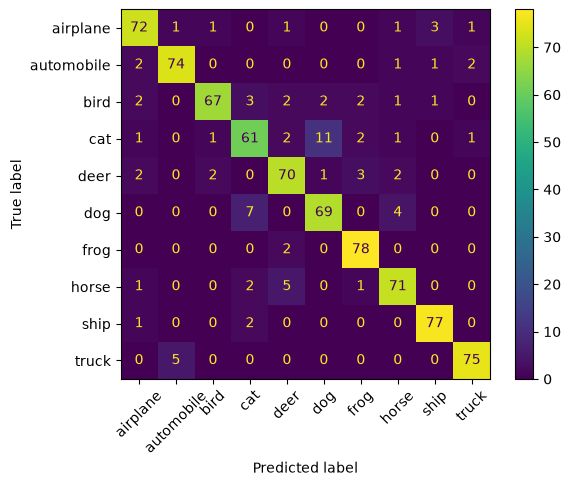

In [8]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000))
# model = LGBMClassifier(n_estimators=300, learning_rate=0.05, verbose=-1, random_state=SEED)

model.fit(X_train, y_train)
pred_val = model.predict(X_val)
print("F1 macro validasi:", round(f1_score(y_val, pred_val, average="macro"), 4))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, xticks_rotation=45)
plt.show()

## Latih ulang di semua data + submission

In [9]:
model.fit(X, y)
predictions = model.predict(X_test)

submission = pd.DataFrame()
submission["id"] = test[ID_COL]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,10000,horse
1,10001,airplane
2,10002,airplane
3,10003,airplane
4,10004,airplane


## Cek dengan kunci jawaban (HAPUS saat lomba)

In [10]:
test_key = pd.read_csv(TEST_KEY_CSV)
print("F1 macro test:", round(f1_score(test_key[TARGET], predictions, average="macro"), 4))

F1 macro test: 0.898
